In [25]:
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [26]:

# Step 3: Download and load the dataset

url = "https://raw.githubusercontent.com/SayamAlt/Company-Bankruptcy-Prediction/main/data.csv"

file_path = "/content/company_bankruptcy.csv"

try:
    urllib.request.urlretrieve(url, file_path)
    df = pd.read_csv(file_path)

    print("Dataset downloaded successfully!")
    print("Dataset shape:", df.shape)
    print("\nFirst five rows:")

    display(df.head())

except Exception as e:
    print("Download failed:", e)


Dataset downloaded successfully!
Dataset shape: (6819, 96)

First five rows:


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [27]:

# Step 4: Inspect the dataset

print("1. Dataset dimensions:")
print(df.shape)

print("\n2. Column names:")
print(df.columns.tolist())

print("\n3. Dataset information:")
df.info()

print("\n4. Missing values:")
print("Total missing values:", df.isnull().sum().sum())

print("\n5. Duplicate rows:")
print(df.duplicated().sum())


1. Dataset dimensions:
(6819, 96)

2. Column names:
['Bankrupt?', ' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue', ' Continuous interest rate (after tax)', ' Operating Expense Rate', ' Research and development expense rate', ' Cash flow rate', ' Interest-bearing debt interest rate', ' Tax rate (A)', ' Net Value Per Share (B)', ' Net Value Per Share (A)', ' Net Value Per Share (C)', ' Persistent EPS in the Last Four Seasons', ' Cash Flow Per Share', ' Revenue Per Share (Yuan ¥)', ' Operating Profit Per Share (Yuan ¥)', ' Per Share Net profit before tax (Yuan ¥)', ' Realized Sales Gross Profit Growth Rate', ' Operating Profit Growth Rate', ' After-tax Net Profit Growth Rate', ' Regular Net 

In [28]:

# Check the bankruptcy labels

print("Bankruptcy status counts:")
print(df["Bankrupt?"].value_counts())

print("\nBankruptcy status percentages:")
print(
    (df["Bankrupt?"].value_counts(normalize=True) * 100).round(2)
)


Bankruptcy status counts:
Bankrupt?
0    6599
1     220
Name: count, dtype: int64

Bankruptcy status percentages:
Bankrupt?
0    96.77
1     3.23
Name: proportion, dtype: float64


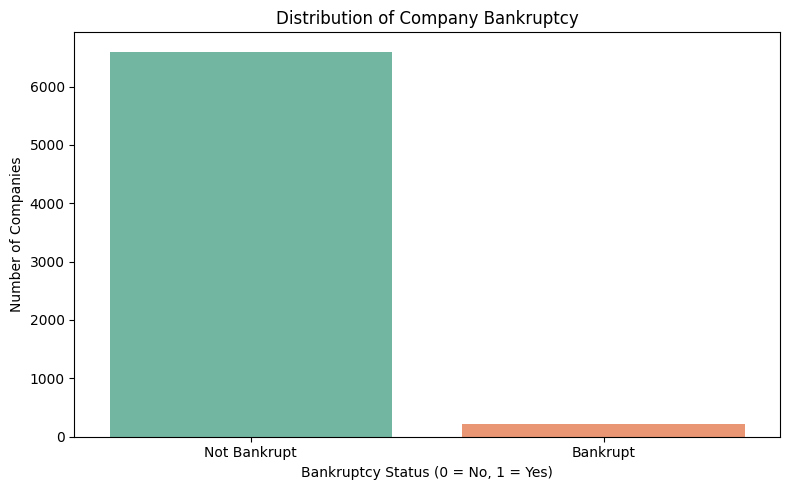

In [29]:

# Step 5: Visualize bankruptcy distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Bankrupt?",
    hue="Bankrupt?",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Company Bankruptcy")
plt.xlabel("Bankruptcy Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Companies")
plt.xticks([0, 1], ["Not Bankrupt", "Bankrupt"])

plt.tight_layout()
plt.show()


In [30]:

# Calculate class percentages

class_counts = df["Bankrupt?"].value_counts()

non_bankrupt = class_counts.get(0, 0)
bankrupt = class_counts.get(1, 0)
total = len(df)

print(f"Total companies: {total}")
print(f"Not bankrupt: {non_bankrupt} ({non_bankrupt / total * 100:.2f}%)")
print(f"Bankrupt: {bankrupt} ({bankrupt / total * 100:.2f}%)")


Total companies: 6819
Not bankrupt: 6599 (96.77%)
Bankrupt: 220 (3.23%)


In [31]:

# Step 6: Prepare features and target

# Financial indicators
X = df.drop(columns=["Bankrupt?"])

# Bankruptcy outcome
y = df["Bankrupt?"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nData splitting completed successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True).round(4))


Features shape: (6819, 95)
Target shape: (6819,)

Data splitting completed successfully!
Training samples: 5455
Testing samples: 1364

Training class distribution:
Bankrupt?
0    0.9677
1    0.0323
Name: proportion, dtype: float64

Testing class distribution:
Bankrupt?
0    0.9677
1    0.0323
Name: proportion, dtype: float64


In [32]:

# Step 7: Train Logistic Regression

# Create a machine learning pipeline
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Train the model using training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [33]:

# Predict bankruptcy on unseen test data

y_pred = logistic_model.predict(X_test)

# Calculate evaluation metrics
print("Logistic Regression Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Not Bankrupt", "Bankrupt"],
    zero_division=0
))


Logistic Regression Results
-----------------------------------
Accuracy:  0.8783
Precision: 0.1856
Recall:    0.8182
F1 Score:  0.3025

Classification Report:
              precision    recall  f1-score   support

Not Bankrupt       0.99      0.88      0.93      1320
    Bankrupt       0.19      0.82      0.30        44

    accuracy                           0.88      1364
   macro avg       0.59      0.85      0.62      1364
weighted avg       0.97      0.88      0.91      1364



In [34]:

# Step 8: Train Support Vector Machine (SVM)

svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

print("SVM trained successfully!")


SVM trained successfully!


In [35]:

# Evaluate SVM on the test data

y_pred_svm = svm_model.predict(X_test)

print("SVM Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_svm, zero_division=0):.4f}")


SVM Results
-----------------------------------
Accuracy:  0.8996
Precision: 0.1879
Recall:    0.6364
F1 Score:  0.2902


In [36]:

# Compare the two models

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "F1 Score": f1_score(y_test, logistic_model.predict(X_test), zero_division=0),
        "Precision": precision_score(y_test, logistic_model.predict(X_test), zero_division=0),
        "Recall": recall_score(y_test, logistic_model.predict(X_test), zero_division=0)
    },
    {
        "Model": "SVM",
        "F1 Score": f1_score(y_test, y_pred_svm, zero_division=0),
        "Precision": precision_score(y_test, y_pred_svm, zero_division=0),
        "Recall": recall_score(y_test, y_pred_svm, zero_division=0)
    }
])

display(comparison.round(4))


,Model,F1 Score,Precision,Recall
0,Logistic Regression,0.3025,0.1856,0.8182
1,SVM,0.2902,0.1879,0.6364


In [37]:

# Step 9: Train K-Nearest Neighbors (KNN)

knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ))
])

knn_model.fit(X_train, y_train)

print("KNN trained successfully!")


KNN trained successfully!


In [38]:

# Evaluate KNN on the test data

y_pred_knn = knn_model.predict(X_test)

print("KNN Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_knn, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_knn, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_knn, zero_division=0):.4f}")


KNN Results
-----------------------------------
Accuracy:  0.9707
Precision: 0.6429
Recall:    0.2045
F1 Score:  0.3103


In [39]:

# Compare Logistic Regression, SVM, and KNN

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision_score(y_test, logistic_model.predict(X_test), zero_division=0),
        "Recall": recall_score(y_test, logistic_model.predict(X_test), zero_division=0),
        "F1 Score": f1_score(y_test, logistic_model.predict(X_test), zero_division=0)
    },
    {
        "Model": "SVM",
        "Precision": precision_score(y_test, y_pred_svm, zero_division=0),
        "Recall": recall_score(y_test, y_pred_svm, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred_svm, zero_division=0)
    },
    {
        "Model": "KNN",
        "Precision": precision_score(y_test, y_pred_knn, zero_division=0),
        "Recall": recall_score(y_test, y_pred_knn, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred_knn, zero_division=0)
    }
])

display(comparison.sort_values("F1 Score", ascending=False).round(4))


,Model,Precision,Recall,F1 Score
2,KNN,0.6429,0.2045,0.3103
0,Logistic Regression,0.1856,0.8182,0.3025
1,SVM,0.1879,0.6364,0.2902


In [40]:

# Step 10: Train Random Forest

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [41]:

# Evaluate Random Forest

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Results")
print("-" * 35)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_rf, zero_division=0):.4f}")


Random Forest Results
-----------------------------------
Accuracy:  0.9721
Precision: 0.7500
Recall:    0.2045
F1 Score:  0.3214


In [42]:

# Compare all four classification models

all_predictions = {
    "Logistic Regression": logistic_model.predict(X_test),
    "SVM": y_pred_svm,
    "KNN": y_pred_knn,
    "Random Forest": y_pred_rf
}

results = []

for name, predictions in all_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.9721,0.7500,0.2045,0.3214
1,KNN,0.9707,0.6429,0.2045,0.3103
2,Logistic Regression,0.8783,0.1856,0.8182,0.3025
3,SVM,0.8996,0.1879,0.6364,0.2902


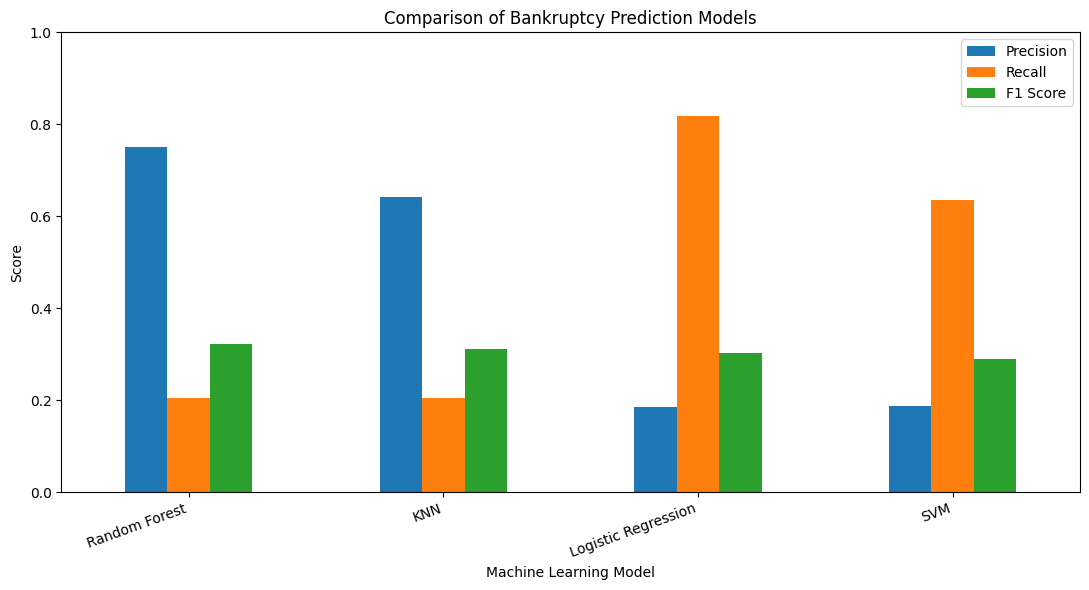

In [43]:

# Step 11: Visualize model performance

metrics = ["Precision", "Recall", "F1 Score"]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1)
)

plt.title("Comparison of Bankruptcy Prediction Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


Best model by F1 score: Random Forest

Classification report:
              precision    recall  f1-score   support

Not Bankrupt       0.97      1.00      0.99      1320
    Bankrupt       0.75      0.20      0.32        44

    accuracy                           0.97      1364
   macro avg       0.86      0.60      0.65      1364
weighted avg       0.97      0.97      0.96      1364



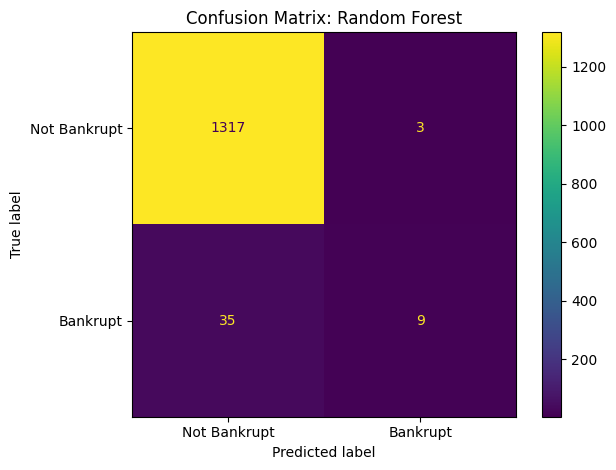

In [44]:

# Step 12: Evaluate the best model from our comparison

best_model_name = results_df.loc[0, "Model"]

model_objects = {
    "Logistic Regression": logistic_model,
    "SVM": svm_model,
    "KNN": knn_model,
    "Random Forest": rf_model
}

best_model = model_objects[best_model_name]
y_pred_best = best_model.predict(X_test)

print("Best model by F1 score:", best_model_name)
print("\nClassification report:")

print(classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=["Not Bankrupt", "Bankrupt"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_best, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Bankrupt", "Bankrupt"]
)

disp.plot(values_format="d")
plt.title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()


In [45]:

# Step 13: Save the trained model and results

import joblib

# Save the best model
joblib.dump(best_model, "/content/best_bankruptcy_model.joblib")

# Save the model comparison table
results_df.to_csv(
    "/content/bankruptcy_model_comparison.csv",
    index=False
)

print("Model saved successfully!")
print("Comparison results saved successfully!")


Model saved successfully!
Comparison results saved successfully!


In [46]:

# Download the saved files

from google.colab import files

files.download("/content/best_bankruptcy_model.joblib")
files.download("/content/bankruptcy_model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>